# 🚜 Predicting Bulldozer Sale Prices with Machine Learning

In this notebook, we build a machine learning model that uses the characteristics of bulldozers and their historical sale prices to predict the sale price of future bulldozers.

| | |
|---|---|
| **Inputs** | Bulldozer characteristics + sale date |
| **Output** | Sale price in USD |
| **Problem type** | **Regression** (predicting a number), with a **time component** (past sales → future sales) |

---
## 📑 Table of Contents

1. [Project framework](#1.-Project-framework) – problem, data, evaluation, features
2. [Setup](#2.-Setup) – imports
3. [Load & explore the data](#3.-Load-&-explore-the-data)
4. [Parse dates & add date features (prototype)](#4.-Parse-dates-&-add-date-features-(prototype))
5. [Quick prototype: pandas categories & missing values](#5.-Quick-prototype:-pandas-categories-&-missing-values)
6. [Proper time-based train/validation split](#6.-Proper-time-based-train/validation-split)
7. [Preprocessing with Scikit-Learn (no leakage)](#7.-Preprocessing-with-Scikit-Learn-(no-leakage))
8. [Baseline model](#8.-Baseline-model)
9. [Evaluation function](#9.-Evaluation-function)
10. [Hyperparameter tuning](#10.-Hyperparameter-tuning)
11. [Compare models](#11.-Compare-models)
12. [Save & load the best model](#12.-Save-&-load-the-best-model)
13. [Feature importance](#13.-Feature-importance) – which columns matter most
14. [Predict on the test set](#14.-Predict-on-the-test-set)
15. [Summary & next steps](#15.-Summary-&-next-steps)

---
# 1. Project framework

### 1.1 Problem definition
> **How well can we predict the future sale price of a bulldozer, given its characteristics and previous sales?**

### 1.2 Data
From the **Blue Book for Bulldozers** Kaggle competition:

* [Dataset on Kaggle](https://www.kaggle.com/competitions/bluebook-for-bulldozers/data)
* [Download from the course GitHub](https://github.com/mrdbourke/zero-to-mastery-ml/raw/refs/heads/master/data/bluebook-for-bulldozers.zip)

| File | Contents | Used for |
|---|---|---|
| `Train.csv` | Sales up to the end of **2011** | Training |
| `Valid.csv` (+ `ValidSolution.csv` for prices) | **Jan 1 – Apr 30, 2012** | Validation / public leaderboard |
| `Test.csv` | **May 1 – Nov 2012** | Final competition evaluation |
| `TrainAndValid.csv` | Train + Valid combined | Exploration only |

### 1.3 Evaluation
The competition metric is **RMSLE** (Root Mean Squared Log Error). It compares the *log* of actual and predicted prices, so it cares about **relative** (percentage) error rather than absolute dollars.
[Kaggle evaluation details](https://www.kaggle.com/competitions/bluebook-for-bulldozers/overview/evaluation)

> 🎯 **Lower RMSLE = better.** Our goal is to minimise it.

### 1.4 Features
Kaggle provides a [data dictionary (Google Sheet)](https://docs.google.com/spreadsheets/d/18ly-bLR8sbDJLITkWG7ozKm8l3RyieQ2Fpgix-beSYI/edit?gid=1021421956#gid=1021421956) describing every column.

---
# 2. Setup
We only need the standard data-science stack here. Scikit-Learn imports appear later, right where they are first used, so you can see *why* each one is needed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Folder where the dataset lives (change this if your data is elsewhere)
DATA_DIR = "data/bluebook-for-bulldozers"

---
# 3. Load & explore the data

We start with `TrainAndValid.csv` (training + validation together) because it is convenient for exploring the data.

> ⚠️ **Important:** this combined file is for **exploration only**. For real modelling we will go back to the separate `Train.csv` / `Valid.csv` files in [Section 6](#6.-Proper-time-based-train/validation-split) so that the model never sees the future.

In [2]:
# Import training + validation data (combined)
df = pd.read_csv(f"{DATA_DIR}/TrainAndValid.csv", low_memory=False)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 412698 entries, 0 to 412697
Data columns (total 53 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   SalesID                   412698 non-null  int64  
 1   SalePrice                 412698 non-null  float64
 2   MachineID                 412698 non-null  int64  
 3   ModelID                   412698 non-null  int64  
 4   datasource                412698 non-null  int64  
 5   auctioneerID              392562 non-null  float64
 6   YearMade                  412698 non-null  int64  
 7   MachineHoursCurrentMeter  147504 non-null  float64
 8   UsageBand                 73670 non-null   str    
 9   saledate                  412698 non-null  str    
 10  fiModelDesc               412698 non-null  str    
 11  fiBaseModel               412698 non-null  str    
 12  fiSecondaryDesc           271971 non-null  str    
 13  fiModelSeries             58667 non-null   str    
 14 

`df.info()` shows column names, data types and non-null counts. Many columns have fewer non-null values than the total rows – those are **missing values**. Let's count them per column.

In [3]:
df.isna().sum()

SalesID                          0
SalePrice                        0
MachineID                        0
ModelID                          0
datasource                       0
auctioneerID                 20136
YearMade                         0
MachineHoursCurrentMeter    265194
UsageBand                   339028
saledate                         0
fiModelDesc                      0
fiBaseModel                      0
fiSecondaryDesc             140727
fiModelSeries               354031
fiModelDescriptor           337882
ProductSize                 216605
fiProductClassDesc               0
state                            0
ProductGroup                     0
ProductGroupDesc                 0
Drive_System                305611
Enclosure                      334
Forks                       214983
Pad_Type                    331602
Ride_Control                259970
Stick                       331602
Transmission                224691
Turbocharged                331602
Blade_Extension     

### 3.1 Sale price over time
Let's plot the first 1000 samples. Right now `saledate` is just text, so the x-axis will look crowded.

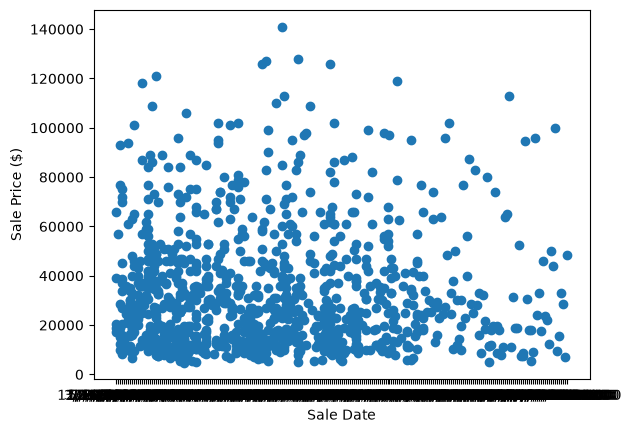

In [4]:
fig, ax = plt.subplots()
ax.scatter(df.saledate[:1000], df.SalePrice[:1000])
ax.set_xlabel("Sale Date")
ax.set_ylabel("Sale Price ($)");

The x-axis is unreadable because Pandas treats each date as a plain **string**. Converting the column to a proper **datetime** fixes that (next section).

### 3.2 Distribution of sale prices

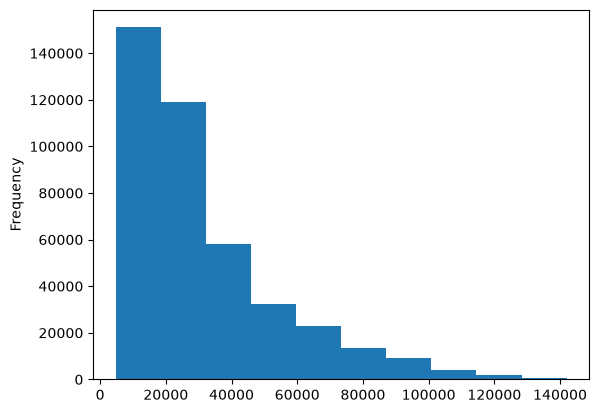

In [5]:
df.SalePrice.plot.hist();

Most bulldozers sell for lower prices, with a long tail of expensive ones (a *right-skewed* distribution). This is one reason RMSLE (which works on log prices) is a sensible metric here.

---
# 4. Parse dates & add date features (prototype)

### 4.1 Parse dates on load
For time-series data, dates matter. Using `parse_dates` tells Pandas to read `saledate` as a real datetime.

In [6]:
df = pd.read_csv(
    f"{DATA_DIR}/TrainAndValid.csv",
    low_memory=False,
    parse_dates=["saledate"],
)
df.saledate.dtype

dtype('<M8[us]')

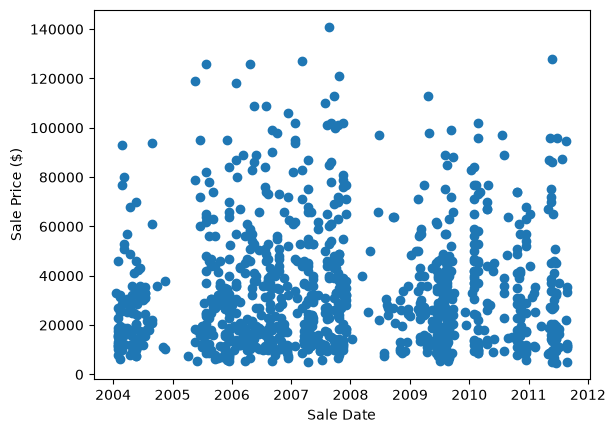

In [7]:
# Same plot as before - now the x-axis is readable
fig, ax = plt.subplots()
ax.scatter(df.saledate[:1000], df.SalePrice[:1000])
ax.set_xlabel("Sale Date")
ax.set_ylabel("Sale Price ($)");

In [8]:
df.head().T   # .T (transpose) makes wide DataFrames easier to read

,0,1,2,3,4
SalesID,1139246,1139248,1139249,1139251,1139253
SalePrice,66000.0,57000.0,10000.0,38500.0,11000.0
MachineID,999089,117657,434808,1026470,1057373
ModelID,3157,77,7009,332,17311
datasource,121,121,121,121,121
auctioneerID,3.0,3.0,3.0,3.0,3.0
YearMade,2004,1996,2001,2001,2007
MachineHoursCurrentMeter,68.0,4640.0,2838.0,3486.0,722.0
UsageBand,Low,Low,High,High,Medium
saledate,2006-11-16 00:00:00,2004-03-26 00:00:00,2004-02-26 00:00:00,2011-05-19 00:00:00,2009-07-23 00:00:00


### 4.2 Sort by date
With time-series data, keep rows in **chronological order**. It makes trends easier to see and avoids accidental mixing of past and future.

In [9]:
df.sort_values(by=["saledate"], inplace=True, ascending=True)
df.saledate.head(20)

205615   1989-01-17
274835   1989-01-31
141296   1989-01-31
212552   1989-01-31
62755    1989-01-31
54653    1989-01-31
81383    1989-01-31
204924   1989-01-31
135376   1989-01-31
113390   1989-01-31
113394   1989-01-31
116419   1989-01-31
32138    1989-01-31
127610   1989-01-31
76171    1989-01-31
127000   1989-01-31
128130   1989-01-31
127626   1989-01-31
55455    1989-01-31
55454    1989-01-31
Name: saledate, dtype: datetime64[us]

### 4.3 Work on a copy
Always keep the original DataFrame untouched so you can go back if something goes wrong.

In [10]:
df_tmp = df.copy()

### 4.4 Extract date features
A model can't do much with a raw date like `2011-03-15`, but it *can* use parts of it: the year, month, day, weekday and day of the year.

In [11]:
df_tmp["saleYear"] = df_tmp.saledate.dt.year
df_tmp["saleMonth"] = df_tmp.saledate.dt.month
df_tmp["saleDay"] = df_tmp.saledate.dt.day
df_tmp["saleDayOfWeek"] = df_tmp.saledate.dt.dayofweek
df_tmp["saleDayOfYear"] = df_tmp.saledate.dt.dayofyear

# The raw date is now redundant, so drop it
df_tmp.drop("saledate", axis=1, inplace=True)

df_tmp.head().T

,205615,274835,141296,212552,62755
SalesID,1646770,1821514,1505138,1671174,1329056
SalePrice,9500.0,14000.0,50000.0,16000.0,22000.0
MachineID,1126363,1194089,1473654,1327630,1336053
ModelID,8434,10150,4139,8591,4089
datasource,132,132,132,132,132
auctioneerID,18.0,99.0,99.0,99.0,99.0
YearMade,1974,1980,1978,1980,1984
MachineHoursCurrentMeter,NaN,NaN,NaN,NaN,NaN
UsageBand,NaN,NaN,NaN,NaN,NaN
fiModelDesc,TD20,A66,D7G,A62,D3B


In [12]:
# Quick look at one categorical column
df_tmp.state.value_counts()

state
Florida           67320
Texas             53110
California        29761
Washington        16222
Georgia           14633
Maryland          13322
Mississippi       13240
Ohio              12369
Illinois          11540
Colorado          11529
New Jersey        11156
North Carolina    10636
Tennessee         10298
Alabama           10292
Pennsylvania      10234
South Carolina     9951
Arizona            9364
New York           8639
Connecticut        8276
Minnesota          7885
Missouri           7178
Nevada             6932
Louisiana          6627
Kentucky           5351
Maine              5096
Indiana            4124
Arkansas           3933
New Mexico         3631
Utah               3046
Unspecified        2801
Wisconsin          2745
New Hampshire      2738
Virginia           2353
Idaho              2025
Oregon             1911
Michigan           1831
Wyoming            1672
Montana            1336
Iowa               1336
Oklahoma           1326
Nebraska            866
West Virgi

---
# 5. Quick prototype: pandas categories & missing values

> 🧪 **Purpose of this section:** learn the core ideas (categories → numbers, filling missing values) in the simplest way possible with Pandas.
> In Sections 6-7 we **redo this properly** with Scikit-Learn and a time-based split to avoid *data leakage*.

### Why build a model this early?
We already know our evaluation metric, so instead of spending ages on manual exploration we let a model help us find patterns. A key goal in ML projects is to **reduce the time between experiments**: the sooner you have a working model, the sooner you can find problems and improve.

We'll use a **Random Forest Regressor** – it works well on tabular data and handles numerical + categorical features once they are prepared.

In [13]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(n_jobs=-1, random_state=42)

# This would fail right now - the data still has strings and missing values:
# model.fit(df_tmp.drop("SalePrice", axis=1), df_tmp.SalePrice)
df_tmp.info()

<class 'pandas.DataFrame'>
Index: 412698 entries, 205615 to 409203
Data columns (total 57 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   SalesID                   412698 non-null  int64  
 1   SalePrice                 412698 non-null  float64
 2   MachineID                 412698 non-null  int64  
 3   ModelID                   412698 non-null  int64  
 4   datasource                412698 non-null  int64  
 5   auctioneerID              392562 non-null  float64
 6   YearMade                  412698 non-null  int64  
 7   MachineHoursCurrentMeter  147504 non-null  float64
 8   UsageBand                 73670 non-null   str    
 9   fiModelDesc               412698 non-null  str    
 10  fiBaseModel               412698 non-null  str    
 11  fiSecondaryDesc           271971 non-null  str    
 12  fiModelSeries             58667 non-null   str    
 13  fiModelDescriptor         74816 non-null   str    
 14 

Random Forests need **numbers with no missing values**. We have two jobs:

1. Turn string columns into numbers
2. Fill in missing values

### 5.1 Strings → pandas categories
The Pandas `category` dtype stores each unique string once and represents rows with integer codes.

In [14]:
# Find the string columns
for label, content in df_tmp.items():
    if pd.api.types.is_string_dtype(content):
        print(label)

UsageBand
fiModelDesc
fiBaseModel
fiSecondaryDesc
fiModelSeries
fiModelDescriptor
ProductSize
fiProductClassDesc
state
ProductGroup
ProductGroupDesc
Drive_System
Enclosure
Forks
Pad_Type
Ride_Control
Stick
Transmission
Turbocharged
Blade_Extension
Blade_Width
Enclosure_Type
Engine_Horsepower
Hydraulics
Pushblock
Ripper
Scarifier
Tip_Control
Tire_Size
Coupler
Coupler_System
Grouser_Tracks
Hydraulics_Flow
Track_Type
Undercarriage_Pad_Width
Stick_Length
Thumb
Pattern_Changer
Grouser_Type
Backhoe_Mounting
Blade_Type
Travel_Controls
Differential_Type
Steering_Controls


In [15]:
# Convert every string column into an (ordered) category
for label, content in df_tmp.items():
    if pd.api.types.is_string_dtype(content):
        df_tmp[label] = content.astype("category").cat.as_ordered()

df_tmp.info()

<class 'pandas.DataFrame'>
Index: 412698 entries, 205615 to 409203
Data columns (total 57 columns):
 #   Column                    Non-Null Count   Dtype   
---  ------                    --------------   -----   
 0   SalesID                   412698 non-null  int64   
 1   SalePrice                 412698 non-null  float64 
 2   MachineID                 412698 non-null  int64   
 3   ModelID                   412698 non-null  int64   
 4   datasource                412698 non-null  int64   
 5   auctioneerID              392562 non-null  float64 
 6   YearMade                  412698 non-null  int64   
 7   MachineHoursCurrentMeter  147504 non-null  float64 
 8   UsageBand                 73670 non-null   category
 9   fiModelDesc               412698 non-null  category
 10  fiBaseModel               412698 non-null  category
 11  fiSecondaryDesc           271971 non-null  category
 12  fiModelSeries             58667 non-null   category
 13  fiModelDescriptor         74816 non-null

Let's see how a single column maps categories to numbers:

In [16]:
print(df_tmp.state.dtype)
df_tmp.state.cat.categories

category


Index(['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California', 'Colorado',
       'Connecticut', 'Delaware', 'Florida', 'Georgia', 'Hawaii', 'Idaho',
       'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana',
       'Maine', 'Maryland', 'Massachusetts', 'Michigan', 'Minnesota',
       'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada',
       'New Hampshire', 'New Jersey', 'New Mexico', 'New York',
       'North Carolina', 'North Dakota', 'Ohio', 'Oklahoma', 'Oregon',
       'Pennsylvania', 'Puerto Rico', 'Rhode Island', 'South Carolina',
       'South Dakota', 'Tennessee', 'Texas', 'Unspecified', 'Utah', 'Vermont',
       'Virginia', 'Washington', 'Washington DC', 'West Virginia', 'Wisconsin',
       'Wyoming'],
      dtype='str')

In [17]:
# The integer code for each row (-1 would mean "missing")
df_tmp.state.cat.codes

205615    43
274835     8
141296     8
212552     8
62755      8
          ..
410879     4
412476     4
411927     4
407124     4
409203     4
Length: 412698, dtype: int8

In [18]:
# Map a category number back to its string
target_state_cat_number = 43
target_state_cat_value = df_tmp.state.cat.categories[target_state_cat_number]
print(f"[INFO] Category number {target_state_cat_number} maps to: {target_state_cat_value}")

[INFO] Category number 43 maps to: Texas


### 5.2 How much data is missing?

In [19]:
# Proportion of missing values per column
df_tmp.isnull().sum() / len(df_tmp)

SalesID                     0.000000
SalePrice                   0.000000
MachineID                   0.000000
ModelID                     0.000000
datasource                  0.000000
auctioneerID                0.048791
YearMade                    0.000000
MachineHoursCurrentMeter    0.642586
UsageBand                   0.821492
fiModelDesc                 0.000000
fiBaseModel                 0.000000
fiSecondaryDesc             0.340993
fiModelSeries               0.857845
fiModelDescriptor           0.818715
ProductSize                 0.524851
fiProductClassDesc          0.000000
state                       0.000000
ProductGroup                0.000000
ProductGroupDesc            0.000000
Drive_System                0.740520
Enclosure                   0.000809
Forks                       0.520921
Pad_Type                    0.803498
Ride_Control                0.629928
Stick                       0.803498
Transmission                0.544444
Turbocharged                0.803498
B

### 5.3 💾 Checkpoint: save the DataFrame
Saving **checkpoints** is good practice – think of them like Git commits: a safe point to return to without repeating earlier steps.

CSV files do **not** preserve Pandas dtypes (our `category` columns would come back as strings). **Parquet** does preserve them, so we use it.

In [20]:
checkpoint_path = f"{DATA_DIR}/TrainAndValid_object_values_as_categories.parquet"

df_tmp.to_parquet(checkpoint_path, index=False, engine="auto")

# Reload to confirm dtypes survived
df_tmp = pd.read_parquet(checkpoint_path, engine="auto")
df_tmp.info()

<class 'pandas.DataFrame'>
RangeIndex: 412698 entries, 0 to 412697
Data columns (total 57 columns):
 #   Column                    Non-Null Count   Dtype   
---  ------                    --------------   -----   
 0   SalesID                   412698 non-null  int64   
 1   SalePrice                 412698 non-null  float64 
 2   MachineID                 412698 non-null  int64   
 3   ModelID                   412698 non-null  int64   
 4   datasource                412698 non-null  int64   
 5   auctioneerID              392562 non-null  float64 
 6   YearMade                  412698 non-null  int64   
 7   MachineHoursCurrentMeter  147504 non-null  float64 
 8   UsageBand                 73670 non-null   category
 9   fiModelDesc               412698 non-null  category
 10  fiBaseModel               412698 non-null  category
 11  fiSecondaryDesc           271971 non-null  category
 12  fiModelSeries             58667 non-null   category
 13  fiModelDescriptor         74816 non-null

### 5.4 Fill missing numeric values
First, which numeric columns contain missing values?

In [21]:
for label, content in df_tmp.items():
    if pd.api.types.is_numeric_dtype(content):
        print(f"{label:30s} | has missing values: {pd.isnull(content).sum() > 0}")

SalesID                        | has missing values: False
SalePrice                      | has missing values: False
MachineID                      | has missing values: False
ModelID                        | has missing values: False
datasource                     | has missing values: False
auctioneerID                   | has missing values: True
YearMade                       | has missing values: False
MachineHoursCurrentMeter       | has missing values: True
saleYear                       | has missing values: False
saleMonth                      | has missing values: False
saleDay                        | has missing values: False
saleDayOfWeek                  | has missing values: False
saleDayOfYear                  | has missing values: False


Only `auctioneerID` and `MachineHoursCurrentMeter` are missing numeric values.

#### Options for handling missing values

| Method | What it does | Useful when |
|---|---|---|
| **Mean** | Replace with column average | No extreme values |
| **Median** | Replace with middle value | General choice, robust to outliers |
| **Mode** | Replace with most common value | Mostly categorical data |
| **Constant** | Replace with a fixed value (e.g. `0`) | `0` has real meaning |
| **Previous / Next value** | Copy nearby value | Time-based data |
| **Other columns** | Calculate from related columns | Columns are related |
| **Interpolation** | Estimate from neighbours | Values follow a trend |
| **Drop the row** | Remove it | Very few rows are affected |

There is **no single best method** – try a few and compare.

#### What we'll use: the **median** + a "was missing" flag
Example: `10, 20, 25, missing, 30, 100`. The mean is dragged up by `100`; the median is not, so the median is a safer fill value.

We'll also add a new column recording *which* values were originally missing, so the model can still use that information:

| Original value | `_is_missing` |
|---:|---:|
| 25 | 0 |
| missing | 1 |
| 30 | 0 |

In [22]:
for label, content in df_tmp.items():
    if pd.api.types.is_numeric_dtype(content):
        if pd.isnull(content).sum():
            # 1) Flag which values were missing
            df_tmp[label + "_is_missing"] = pd.isnull(content).astype(int)
            # 2) Fill with the median
            df_tmp[label] = content.fillna(content.median())

In [23]:
# Sanity check: look at some rows that were missing MachineHoursCurrentMeter
df_tmp[df_tmp["MachineHoursCurrentMeter_is_missing"] == 1].sample(5)

,SalesID,SalePrice,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,fiModelDesc,...,Travel_Controls,Differential_Type,Steering_Controls,saleYear,saleMonth,saleDay,saleDayOfWeek,saleDayOfYear,auctioneerID_is_missing,MachineHoursCurrentMeter_is_missing
272066,1810588,13000.0,1226348,9578,132,1.0,2004,0.0,NaN,S185,...,NaN,NaN,NaN,2008,8,6,2,219,0,1
226536,1290339,17500.0,1275715,3177,132,15.0,1992,0.0,NaN,580SUPER K,...,NaN,NaN,NaN,2007,4,12,3,102,0,1
236677,1544384,87500.0,884761,1218,132,7.0,2003,0.0,NaN,325CL,...,NaN,NaN,NaN,2007,9,5,2,248,0,1
103973,1762680,29000.0,1047720,580,132,1.0,1996,0.0,NaN,WA120-1,...,NaN,Standard,Conventional,2000,12,13,2,348,0,1
170247,1514236,107500.0,412062,3371,132,1.0,1993,0.0,NaN,14G,...,NaN,NaN,NaN,2004,10,8,4,282,0,1


In [24]:
# Any numeric columns still missing values? (should print nothing)
for label, content in df_tmp.items():
    if pd.api.types.is_numeric_dtype(content):
        if pd.isnull(content).sum():
            print(f"Column still missing values: {label}")

# How many auctioneerID values were missing?
df_tmp.auctioneerID_is_missing.value_counts()

auctioneerID_is_missing
0    392562
1     20136
Name: count, dtype: int64

### 5.5 Fill missing categorical values & convert to numbers
Pandas uses `-1` as the code for a missing category and starts real categories at `0`. We add `1` so that **missing → 0** and real categories start at **1**.

In [25]:
print("[INFO] Columns which are not numeric:")
for label, content in df_tmp.items():
    if not pd.api.types.is_numeric_dtype(content):
        print(f"{label:30s} | {df_tmp[label].dtype.name}")

[INFO] Columns which are not numeric:
UsageBand                      | category
fiModelDesc                    | category
fiBaseModel                    | category
fiSecondaryDesc                | category
fiModelSeries                  | category
fiModelDescriptor              | category
ProductSize                    | category
fiProductClassDesc             | category
state                          | category
ProductGroup                   | category
ProductGroupDesc               | category
Drive_System                   | category
Enclosure                      | category
Forks                          | category
Pad_Type                       | category
Ride_Control                   | category
Stick                          | category
Transmission                   | category
Turbocharged                   | category
Blade_Extension                | category
Blade_Width                    | category
Enclosure_Type                 | category
Engine_Horsepower              | categ

In [26]:
for label, content in df_tmp.items():
    if not pd.api.types.is_numeric_dtype(content):
        # Flag which values were missing
        df_tmp[label + "_is_missing"] = pd.isnull(content).astype(int)
        # Categories -> integer codes (+1 so missing becomes 0)
        df_tmp[label] = pd.Categorical(content).codes + 1

df_tmp.info()

<class 'pandas.DataFrame'>
RangeIndex: 412698 entries, 0 to 412697
Columns: 103 entries, SalesID to Steering_Controls_is_missing
dtypes: float64(3), int16(4), int32(5), int64(51), int8(40)
memory usage: 196.8 MB


In [27]:
df_tmp.isna().sum().sum()   # total missing values left - should be 0

np.int64(0)

✅ All data is now numeric with no missing values, so a model *could* be trained on it.

### ⚠️ But there is a problem: data leakage
We calculated medians from the **combined** train+validation data. That means information from the *validation period* (the "future") influenced how we prepared the training data. The validation score would then look better than it should.

**The fix:** split by date first, then learn all preprocessing values (medians, category mappings) from the **training set only**.

---
# 6. Proper time-based train/validation split

Our goal is to **use the past to predict the future**. A random split would let the model train on data from *after* some of its validation samples. Instead, we use the competition's original date-based files:

* **Training** (`Train.csv`) → sales up to 2011
* **Validation** (`Valid.csv`) → Jan 1 – Apr 30, 2012
* **Test** (`Test.csv`) → May 1 – Nov 2012

> 🔑 **Key idea:** the validation set represents the future, so the training process must not learn *anything* from it.

For reference, the quick-and-dirty split from the combined data would look like this (we won't use it):

In [28]:
# (For comparison only) split the prototype DataFrame by year
df_val_proto = df_tmp[df_tmp.saleYear == 2012]
df_train_proto = df_tmp[df_tmp.saleYear != 2012]
len(df_train_proto), len(df_val_proto)

(401125, 11573)

Now the real thing. `ValidSolution.csv` holds the true sale prices for `Valid.csv`, so we merge them.

In [2]:
# Training samples (parse dates, sort chronologically)
train_df = pd.read_csv(
    f"{DATA_DIR}/Train.csv",
    parse_dates=["saledate"],
    low_memory=False,
).sort_values(by="saledate", ascending=True)

# Validation samples
valid_df = pd.read_csv(f"{DATA_DIR}/Valid.csv", parse_dates=["saledate"])

# True prices for the validation samples
valid_solution = pd.read_csv(f"{DATA_DIR}/ValidSolution.csv")

# Attach the prices to the validation features
valid_df = valid_df.merge(valid_solution[["SalesID", "SalePrice"]], on="SalesID", how="left")

# Keep validation chronological too
valid_df = valid_df.sort_values("saledate", ascending=True).reset_index(drop=True)

print(f"[INFO] Training samples:   {len(train_df)}")
print(f"[INFO] Validation samples: {len(valid_df)}")

[INFO] Training samples:   401125
[INFO] Validation samples: 11573


In [30]:
train_df.sample(5)

,SalesID,SalePrice,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,saledate,...,Undercarriage_Pad_Width,Stick_Length,Thumb,Pattern_Changer,Grouser_Type,Backhoe_Mounting,Blade_Type,Travel_Controls,Differential_Type,Steering_Controls
383186,4301112,37000,684820,1096,172,1.0,2004,1725.0,Low,2010-07-29,...,24 inch,None or Unspecified,Hydraulic,Yes,Triple,NaN,NaN,NaN,NaN,NaN
320895,2304477,18000,510424,13395,136,NaN,2006,0.0,NaN,2007-10-20,...,None or Unspecified,None or Unspecified,Manual,Yes,Double,NaN,NaN,NaN,NaN,NaN
278799,1845659,6500,1378788,18472,132,1.0,2003,NaN,NaN,2007-05-09,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
277228,1832591,18000,1270072,17798,132,2.0,1000,NaN,NaN,2003-09-11,...,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN,NaN
70250,1348309,9500,1483367,4146,132,22.0,1961,NaN,NaN,2001-04-19,...,NaN,NaN,NaN,NaN,NaN,None or Unspecified,Straight,None or Unspecified,NaN,NaN


In [31]:
valid_df.sample(5)

,SalesID,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,saledate,fiModelDesc,...,Stick_Length,Thumb,Pattern_Changer,Grouser_Type,Backhoe_Mounting,Blade_Type,Travel_Controls,Differential_Type,Steering_Controls,SalePrice
3250,6300662,1810901,2144,149,1,2007,NaN,NaN,2012-02-13,SK210LC,...,None or Unspecified,Manual,None or Unspecified,Double,NaN,NaN,NaN,NaN,NaN,75000.0
9898,4283020,2279117,3380,172,1,1986,11468.0,Medium,2012-04-02,16G,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,75000.0
2502,4265605,2273818,13854,172,1,1991,13945.0,Medium,2012-02-12,D6HII,...,NaN,NaN,NaN,NaN,None or Unspecified,Semi U,Differential Steer,NaN,NaN,37000.0
10334,6258428,1827834,13244,149,2,1000,NaN,NaN,2012-04-10,580LII,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21500.0
10809,6264213,404974,1623,149,15,2001,NaN,NaN,2012-04-18,D6MLGP,...,NaN,NaN,NaN,NaN,None or Unspecified,None or Unspecified,Finger Tip,NaN,NaN,39000.0


### 6.1 Reusable date-feature function
We repeat the date feature engineering from Section 4, but now as a **function**, so exactly the same steps are applied to train, validation *and* test data.

> **Key idea:** apply identical feature engineering to every dataset, so the model always sees the same kind of features.

| Feature | Meaning |
|---|---|
| `saleYear` | Year of the sale |
| `saleMonth` | Month |
| `saleDay` | Day of the month |
| `saleDayofweek` | 0 = Monday ... 6 = Sunday |
| `saleDayofyear` | Day of the year |

In [3]:
def add_datetime_features_to_df(df, date_column="saledate"):
    """Add year/month/day/weekday/day-of-year columns and drop the raw date."""
    df["saleYear"] = df[date_column].dt.year
    df["saleMonth"] = df[date_column].dt.month
    df["saleDay"] = df[date_column].dt.day
    df["saleDayofweek"] = df[date_column].dt.dayofweek
    df["saleDayofyear"] = df[date_column].dt.dayofyear

    df.drop(date_column, axis=1, inplace=True)
    return df

train_df = add_datetime_features_to_df(train_df)
valid_df = add_datetime_features_to_df(valid_df)

# Look at the 5 newly added columns
train_df.iloc[:, -5:].sample(5)

,saleYear,saleMonth,saleDay,saleDayofweek,saleDayofyear
63419,2004,2,9,0,40
100008,2002,3,20,2,79
363751,2010,5,6,3,126
24603,1993,4,21,2,111
198487,2009,5,20,2,140


---
# 7. Preprocessing with Scikit-Learn (no leakage)

Earlier we encoded categories with Pandas. Scikit-Learn offers well-tested preprocessing tools that can be reused on any new data, which is exactly what we need for validation and test sets.

### 7.1 Split into features (X) and labels (y)

In [24]:
X_train = train_df.drop("SalePrice", axis=1)
y_train = train_df["SalePrice"]

X_valid = valid_df.drop("SalePrice", axis=1)
y_valid = valid_df["SalePrice"]

### 7.2 Identify feature types
Different feature types need different preprocessing:

* **Numerical** → may have missing values → *impute* (fill)
* **Categorical** → must become numbers → *encode*

In [25]:
numerical_features = [c for c, content in X_train.items() if pd.api.types.is_numeric_dtype(content)]
categorical_features = [c for c, content in X_train.items() if not pd.api.types.is_numeric_dtype(content)]

print(f"[INFO] {len(numerical_features)} numeric features: {numerical_features}")
print(f"[INFO] {len(categorical_features)} categorical features, e.g. {categorical_features[:10]}...")

[INFO] 12 numeric features: ['SalesID', 'MachineID', 'ModelID', 'datasource', 'auctioneerID', 'YearMade', 'MachineHoursCurrentMeter', 'saleYear', 'saleMonth', 'saleDay', 'saleDayofweek', 'saleDayofyear']
[INFO] 44 categorical features, e.g. ['UsageBand', 'fiModelDesc', 'fiBaseModel', 'fiSecondaryDesc', 'fiModelSeries', 'fiModelDescriptor', 'ProductSize', 'fiProductClassDesc', 'state', 'ProductGroup']...


### 7.3 Encode categorical features
Converting categories to numbers is called **encoding**:

```text
"Cat"  → 0
"Dog"  → 1
"Bird" → 2
```

| Encoder | What it does | Typical use |
|---|---|---|
| `LabelEncoder` | Integer for each *target* label | Classification targets |
| `OneHotEncoder` | One binary column per category | Categorical features |
| `OrdinalEncoder` | One integer per category | Categorical features |
| `TargetEncoder` | Uses the target to encode | High-cardinality categoricals |

We use **`OrdinalEncoder`**, configured so that **missing and previously-unseen categories become `-1`**.

### 7.4 The golden rule: learn from TRAIN only

```text
Training data
     │
     ├── learn category mappings   (fit)
     ├── learn numeric medians     (fit)
     ▼
Transform training data ─────────► Transform validation / test data
                                   using the SAME learned values
```

* `fit_transform()` on training data = learn **and** apply
* `transform()` on validation/test data = apply only (never learn)

In [26]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_encoder = OrdinalEncoder(
    categories="auto",
    handle_unknown="use_encoded_value",  # unseen categories ...
    unknown_value=-1,                    # ... become -1
    encoded_missing_value=-1,            # missing categories also become -1
)

# LEARN the category mappings from the training data only
ordinal_encoder.fit(X_train[categorical_features])

,"handle_unknown handle_unknown: {'error', 'use_encoded_value'}, default='error'When set to 'error' an error will be raised in case an unknowncategorical feature is present during transform. When set to'use_encoded_value', the encoded value of unknown categories will beset to the value given for the parameter `unknown_value`. In:meth:`inverse_transform`, an unknown category will be denoted as None... versionadded:: 0.24",'use_encoded_value'
,"unknown_value unknown_value: int or np.nan, default=NoneWhen the parameter handle_unknown is set to 'use_encoded_value', thisparameter is required and will set the encoded value of unknowncategories. It has to be distinct from the values used to encode any ofthe categories in `fit`. If set to np.nan, the `dtype` parameter mustbe a float dtype... versionadded:: 0.24",-1
,"encoded_missing_value encoded_missing_value: int or np.nan, default=np.nanEncoded value of missing categories. If set to `np.nan`, then the `dtype`parameter must be a float dtype... versionadded:: 1.1",-1
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute.",'auto'
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.3 Read more in the :ref:`User Guide <encoder_infrequent_categories>`.",None
,"max_categories max_categories: int, default=NoneSpecifies an upper limit to the number of output categories for each inputfeature when considering infrequent categories. If there are infrequentcategories, `max_categories` includes the category representing theinfrequent categories along with the frequent categories. If `None`,there is no limit to the number of output features.`max_categories` do **not** take into account missing or unknowncategories. Setting `unknown_value` or `encoded_missing_value` to aninteger will increase the number of unique integer codes by one each.This can result in up to `max_categories + 2` integer codes... versionadded:: 1.3 Read more in the :ref:`User Guide <encoder_infrequent_categories>`.",None
Name,Type,Value
categories_ categories_: list of arraysThe categories of each feature determined during ``fit`` (in order ofthe features in X and corresponding with the output of ``transform``).This does not include categories that weren't seen during ``fit``.,list,"[array(['High'... dtype=object), array(['100C'... dtype=object), array(['10', ... dtype=object), array([' MSR ... dtype=object), ...]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](44,)","['UsageBand','fiModelDesc','fiBaseModel',...,'Travel_Controls', 'Differential_Type','Steering_Controls']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 1.0,int,44


### 7.5 Learn numeric medians (from training data)
We compute the median of every numeric column **on the training set**, and note which columns have missing values in training (they will get an `_is_missing` flag).

In [27]:
# Median of each numeric column, learned from training data only
train_medians = X_train[numerical_features].median()

# Columns that have missing values in training -> get a "_is_missing" flag
cols_with_missing = [c for c in numerical_features if X_train[c].isna().any()]
print(f"[INFO] Numeric columns with missing values in training: {cols_with_missing}")

[INFO] Numeric columns with missing values in training: ['auctioneerID', 'MachineHoursCurrentMeter']


### 7.6 One reusable preprocessing function
Rather than copy/pasting code for each dataset, we wrap the steps in a function. It uses **only** the encoder and medians learned above, so it is safe to apply to training, validation and test data.

In [28]:
def preprocess(X):
    """Apply the preprocessing learned from the training data to any DataFrame X."""
    X = X.copy()

    # 1) Record which numeric values were missing (1 = missing, 0 = present)
    for col in cols_with_missing:
        X[col + "_is_missing"] = X[col].isna().astype(int)

    # 2) Fill numeric missing values with the TRAINING medians
    X[numerical_features] = X[numerical_features].fillna(train_medians)

    # 3) Encode categories with the encoder fitted on TRAINING data
    X[categorical_features] = ordinal_encoder.transform(X[categorical_features])

    return X

X_train_preprocessed = preprocess(X_train)
X_valid_preprocessed = preprocess(X_valid)

X_train_preprocessed.head()

,SalesID,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,fiModelDesc,fiBaseModel,...,Travel_Controls,Differential_Type,Steering_Controls,saleYear,saleMonth,saleDay,saleDayofweek,saleDayofyear,auctioneerID_is_missing,MachineHoursCurrentMeter_is_missing
205615,1646770,1126363,8434,132,18.0,1974,0.0,-1.0,4536.0,1734.0,...,5.0,-1.0,-1.0,1989,1,17,1,17,0,1
92803,1404019,1169900,7110,132,99.0,1986,0.0,-1.0,734.0,242.0,...,-1.0,-1.0,-1.0,1989,1,31,1,31,0,1
98346,1415646,1262088,3357,132,99.0,1975,0.0,-1.0,81.0,18.0,...,-1.0,-1.0,-1.0,1989,1,31,1,31,0,1
169297,1596358,1433229,8247,132,99.0,1978,0.0,-1.0,1157.0,348.0,...,-1.0,3.0,1.0,1989,1,31,1,31,0,1
274835,1821514,1194089,10150,132,99.0,1980,0.0,-1.0,1799.0,556.0,...,-1.0,3.0,1.0,1989,1,31,1,31,0,1


In [9]:
# Sanity checks: same columns in both sets, and no missing values left
assert list(X_train_preprocessed.columns) == list(X_valid_preprocessed.columns)
print("Missing values (train):", X_train_preprocessed.isna().sum().sum())
print("Missing values (valid):", X_valid_preprocessed.isna().sum().sum())

X_train_preprocessed.shape, y_train.shape, X_valid_preprocessed.shape, y_valid.shape

Missing values (train): 0
Missing values (valid): 0


((401125, 58), (401125,), (11573, 58), (11573,))

---
# 8. Baseline model

Our first real model: a `RandomForestRegressor`. We use `max_samples=10000` so each tree only sees 10,000 rows – this makes training much **faster** at the cost of a little accuracy, which is perfect for quick experiments.

In [39]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_jobs=-1,          # use all CPU cores
    random_state=42,    # reproducible results
    max_samples=10000,  # each tree trains on 10,000 random rows
)

model.fit(X_train_preprocessed, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"max_samples max_samples: int or float, default=NoneIf bootstrap is True, the number of samples to draw from Xto train each base estimator.- If None (default), then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples... versionadded:: 0.22.. versionchanged:: 1.9 Float `max_samples` is relative to `sample_weight.sum()` instead of `X.shape[0]` for weighted samples.",10000
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", th

In [40]:
# R^2 on training and validation data (1.0 = perfect)
print("Train R^2:", model.score(X_train_preprocessed, y_train))
print("Valid R^2:", model.score(X_valid_preprocessed, y_valid))

Train R^2: 0.8610148853804225
Valid R^2: 0.8350662154699645


💡 A higher **train** score than **validation** score is normal. A *big* gap suggests **overfitting** (the model memorised the training data). We'll look at more metrics next.

---
# 9. Evaluation function

`R^2` alone isn't enough. We'll report three metrics for both training and validation sets:

| Metric | Meaning | Better is |
|---|---|---|
| **MAE** | Average absolute error in dollars | Lower |
| **RMSLE** | Competition metric (relative error) | Lower |
| **R^2** | Share of variance explained | Higher (max 1.0) |

In [11]:
from sklearn.metrics import mean_squared_log_error, mean_absolute_error, r2_score

def show_scores(model,
                X_train=X_train_preprocessed, y_train=y_train,
                X_valid=X_valid_preprocessed, y_valid=y_valid):
    """Return a dictionary of training and validation scores for a fitted model."""
    train_preds = model.predict(X_train)
    valid_preds = model.predict(X_valid)

    return {
        "Training MAE":     mean_absolute_error(y_train, train_preds),
        "Validation MAE":   mean_absolute_error(y_valid, valid_preds),
        "Training RMSLE":   np.sqrt(mean_squared_log_error(y_train, train_preds)),
        "Validation RMSLE": np.sqrt(mean_squared_log_error(y_valid, valid_preds)),
        "Training R^2":     r2_score(y_train, train_preds),
        "Valid R^2":        r2_score(y_valid, valid_preds),
    }

In [ ]:
model_scores = show_scores(model)
model_scores

---
# 10. Hyperparameter tuning

**Hyperparameters** are model settings you choose *before* training (e.g. number of trees). `RandomizedSearchCV` tries random combinations from a grid, scores each with cross-validation, and keeps the best.

| Hyperparameter | What it controls |
|---|---|
| `n_estimators` | Number of trees |
| `max_depth` | How deep each tree can grow |
| `min_samples_split` | Min samples needed to split a node |
| `min_samples_leaf` | Min samples required at a leaf |
| `max_features` | Features considered at each split |
| `max_samples` | Rows each tree trains on (kept at 10,000 for speed) |

### 10.1 Randomized search

In [42]:
from sklearn.model_selection import RandomizedSearchCV

rf_grid = {
    "n_estimators": np.arange(100, 1000, 100),
    "max_depth": [None, 10, 20],
    "min_samples_split": np.arange(2, 10, 1),
    "min_samples_leaf": np.arange(1, 10, 1),
    "max_features": [0.5, 1, "sqrt"],
    "max_samples": [10000],
}

rs_model = RandomizedSearchCV(
    estimator=RandomForestRegressor(),
    param_distributions=rf_grid,
    n_iter=20,        # try 20 random combinations
    cv=3,             # 3-fold cross-validation
    verbose=3,
    random_state=42,
    n_jobs=3,
)

rs_model.fit(X_train_preprocessed, y_train)   # this can take a while

Fitting 3 folds for each of 20 candidates, totalling 60 fits
[CV 2/3] END max_depth=None, max_features=1, max_samples=10000, min_samples_leaf=3, min_samples_split=9, n_estimators=600;, score=0.597 total time=  12.1s
[CV 3/3] END max_depth=None, max_features=1, max_samples=10000, min_samples_leaf=3, min_samples_split=9, n_estimators=600;, score=0.556 total time=  12.1s
[CV 1/3] END max_depth=None, max_features=1, max_samples=10000, min_samples_leaf=3, min_samples_split=9, n_estimators=600;, score=0.461 total time=  12.3s
[CV 1/3] END max_depth=20, max_features=sqrt, max_samples=10000, min_samples_leaf=3, min_samples_split=8, n_estimators=900;, score=0.533 total time=  33.6s
[CV 3/3] END max_depth=20, max_features=sqrt, max_samples=10000, min_samples_leaf=3, min_samples_split=8, n_estimators=900;, score=0.645 total time=  33.7s
[CV 2/3] END max_depth=20, max_features=sqrt, max_samples=10000, min_samples_leaf=3, min_samples_split=8, n_estimators=900;, score=0.726 total time=  35.3s
[CV 1/

/home/ismile/Desktop/development/machine-learning/ml-bulldozer-price/.venv/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[CV 1/3] END max_depth=20, max_features=sqrt, max_samples=10000, min_samples_leaf=1, min_samples_split=2, n_estimators=800;, score=0.542 total time=  38.8s
[CV 3/3] END max_depth=20, max_features=sqrt, max_samples=10000, min_samples_leaf=1, min_samples_split=2, n_estimators=800;, score=0.643 total time=  38.6s
[CV 2/3] END max_depth=20, max_features=sqrt, max_samples=10000, min_samples_leaf=1, min_samples_split=2, n_estimators=800;, score=0.740 total time=  40.4s
[CV 1/3] END max_depth=10, max_features=sqrt, max_samples=10000, min_samples_leaf=8, min_samples_split=5, n_estimators=200;, score=0.496 total time=   5.9s
[CV 2/3] END max_depth=10, max_features=sqrt, max_samples=10000, min_samples_leaf=8, min_samples_split=5, n_estimators=200;, score=0.660 total time=   5.8s
[CV 3/3] END max_depth=10, max_features=sqrt, max_samples=10000, min_samples_leaf=8, min_samples_split=5, n_estimators=200;, score=0.625 total time=   5.8s
[CV 1/3] END max_depth=10, max_features=1, max_samples=10000, mi

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestRegressor()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [None, 10, ...], 'max_features': [0.5, 1, ...], 'max_samples': [10000], 'min_samples_leaf': array([1, 2, ..., 6, 7, 8, 9]), ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",3
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichretur

In [43]:
rs_model.best_params_

{'n_estimators': np.int64(500),
 'min_samples_split': np.int64(8),
 'min_samples_leaf': np.int64(2),
 'max_samples': 10000,
 'max_features': 0.5,
 'max_depth': None}

In [44]:
rs_model_scores = show_scores(rs_model)   # uses the best model found
rs_model_scores

{'Training MAE': 5833.955257592315,
 'Validation MAE': 7214.543926464662,
 'Training RMSLE': np.float64(0.26734990496509864),
 'Validation RMSLE': np.float64(0.29666380937648146),
 'Training R^2': 0.8481769076649297,
 'Valid R^2': 0.8320903965394981}

> 📝 **Note on cross-validation & time:** `cv=3` here does not strictly respect time order, so some folds train on later data than they validate on. For a stricter setup you could use `sklearn.model_selection.TimeSeriesSplit`. We keep `cv=3` for simplicity; our *final* validation set (Jan-Apr 2012) is still a proper "future" check.

### 10.2 Train a model with the best hyperparameters
Using the values found by the search (your numbers may differ slightly if you re-run the search), we train a final model. Unlike the baseline, it uses **all** training rows per tree (no `max_samples`), so it is slower but usually more accurate.

In [46]:
%%time
ideal_model = RandomForestRegressor(
    n_estimators=500,
    max_depth=None,
    min_samples_split=8,
    min_samples_leaf=2,
    max_features=0.5,
    random_state=42,
    n_jobs=3,
)

ideal_model.fit(X_train_preprocessed, y_train)

CPU times: user 19min 17s, sys: 2.99 s, total: 19min 20s
Wall time: 6min 28s


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",8
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"ma

In [47]:
ideal_model_scores = show_scores(ideal_model)
ideal_model_scores

{'Training MAE': 2495.9101818830327,
 'Validation MAE': 5868.098751588197,
 'Training RMSLE': np.float64(0.12698009209718406),
 'Validation RMSLE': np.float64(0.2424907577962353),
 'Training R^2': 0.9687338971211342,
 'Valid R^2': 0.8842155775869487}

---
# 11. Compare models
Put all scores in one table, then plot the **validation RMSLE** (the competition metric; lower is better).

In [48]:
model_scores["model_name"] = "default_model"
rs_model_scores["model_name"] = "randomized_search_model"
ideal_model_scores["model_name"] = "ideal_model"

model_comparison_df = pd.DataFrame(
    [model_scores, rs_model_scores, ideal_model_scores]
).sort_values(by="Validation RMSLE", ascending=False)

model_comparison_df

,Training MAE,Validation MAE,Training RMSLE,Validation RMSLE,Training R^2,Valid R^2,model_name
1,5833.955258,7214.543926,0.267350,0.296664,0.848177,0.832090,randomized_search_model
0,5558.013940,7132.862672,0.257701,0.293821,0.861015,0.835066,default_model
2,2495.910182,5868.098752,0.126980,0.242491,0.968734,0.884216,ideal_model


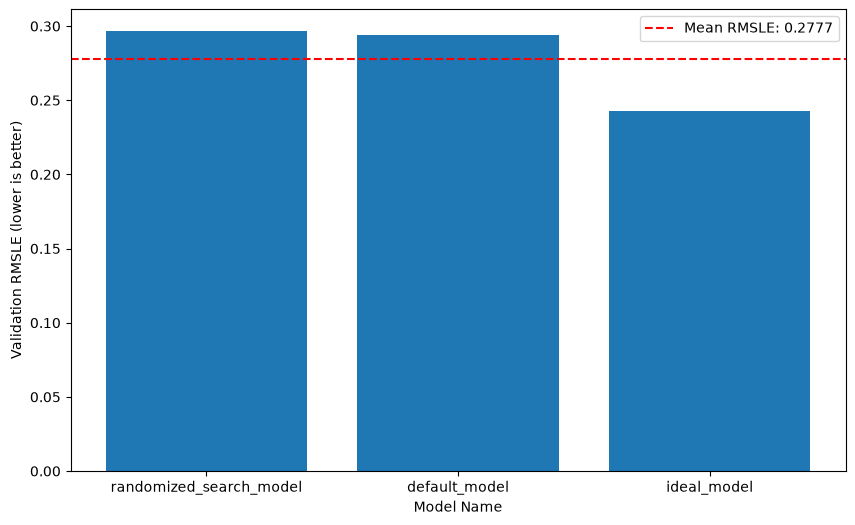

In [49]:
mean_rmsle_score = model_comparison_df["Validation RMSLE"].mean()

plt.figure(figsize=(10, 6))
plt.bar(model_comparison_df["model_name"], model_comparison_df["Validation RMSLE"])
plt.xlabel("Model Name")
plt.ylabel("Validation RMSLE (lower is better)")
plt.axhline(y=mean_rmsle_score, color="red", linestyle="--",
            label=f"Mean RMSLE: {mean_rmsle_score:.4f}")
plt.legend();

---
# 12. Save & load the best model
`joblib` saves a trained model to disk so you can reuse it later without retraining.

In [ ]:
import joblib

bulldozer_price_model_filename = "models/randomforest_regressor_best_RMSLE.pkl"

joblib.dump(value=ideal_model, filename=bulldozer_price_model_filename)

In [14]:
# Load it back and confirm it behaves identically
best_model = joblib.load(bulldozer_price_model_filename)
best_model_scores = show_scores(best_model)
best_model_scores

{'Training MAE': 2495.9101818830327,
 'Validation MAE': 5868.098751588197,
 'Training RMSLE': np.float64(0.12698009209718406),
 'Validation RMSLE': np.float64(0.2424907577962353),
 'Training R^2': 0.9687338971211342,
 'Valid R^2': 0.8842155775869487}

> 💡 The model alone is not enough for future predictions: the **encoder and medians** are part of the pipeline too. If you plan to reuse this later, also save them: `joblib.dump(ordinal_encoder, "encoder.pkl")` and `joblib.dump(train_medians, "medians.pkl")`.

---
# 13. Feature importance

**Feature importance** tells us which attributes of the data mattered most when predicting the target (`SalePrice`). It helps us:

* understand what drives bulldozer prices,
* spot useless columns we could drop,
* sanity-check the model (does it rely on things that make sense?).

A Random Forest calculates this automatically: each feature's score reflects how much it reduced prediction error across all the trees. The scores add up to 1, so a higher number means a more important feature.

### 13.1 Raw importances
One number per column of `X_train_preprocessed`, in the same order as its columns:

In [ ]:
best_model.feature_importances_

A bare array isn't very readable, so let's write a helper that pairs each importance with its column name, sorts them, and plots the top `n` as a horizontal bar chart.

In [2]:
def plot_feature_importances(columns, importances, n=20):
    """Plot the top n feature importances."""
    df = (
        pd.DataFrame({"features": columns, "importance": importances})
        .sort_values("importance", ascending=False)
        .reset_index(drop=True)
    )

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(df["features"][:n], df["importance"][:n])
    ax.set_xlabel("Feature Importance")
    ax.set_ylabel("Feature")
    ax.set_title(f"Top {n} Feature Importances")
    ax.invert_yaxis()   # most important feature at the top
    plt.show()

### 13.2 Plot the top 20 features

In [ ]:
plot_feature_importances(X_train_preprocessed.columns, best_model.feature_importances_)

**How to read this chart**

* The longer the bar, the more the model relied on that feature.
* Check the data dictionary (Section 1.4) to see what the top columns mean, and ask whether they make sense for bulldozer prices (e.g. age, size and model type usually matter).
* Features with tiny importances add little; you could try dropping them and see whether the validation RMSLE changes.

> ⚠️ Importances show what the *model* used, not necessarily what *causes* prices to change. Also, Random Forest importances can favour columns with many unique values (like IDs), so treat them as a guide rather than a final answer.

---
# 14. Predict on the test set

`Test.csv` covers May-Nov 2012 and has **no `SalePrice`** column. We prepare it with the **exact same steps** as training/validation:

1. Parse dates → 2. add date features → 3. apply `preprocess()` (training-learned values) → 4. predict.

In [15]:
test_df = pd.read_csv(
    f"{DATA_DIR}/Test.csv",
    parse_dates=["saledate"],
    low_memory=False
)
test_df.head()

,SalesID,MachineID,ModelID,datasource,auctioneerID,YearMade,MachineHoursCurrentMeter,UsageBand,saledate,fiModelDesc,...,Undercarriage_Pad_Width,Stick_Length,Thumb,Pattern_Changer,Grouser_Type,Backhoe_Mounting,Blade_Type,Travel_Controls,Differential_Type,Steering_Controls
0,1227829,1006309,3168,121,3,1999,3688.0,Low,2012-05-03,580G,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1227844,1022817,7271,121,3,1000,28555.0,High,2012-05-10,936,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,Conventional
2,1227847,1031560,22805,121,3,2004,6038.0,Medium,2012-05-10,EC210BLC,...,None or Unspecified,"9' 6""",Manual,None or Unspecified,Double,NaN,NaN,NaN,NaN,NaN
3,1227848,56204,1269,121,3,2006,8940.0,High,2012-05-10,330CL,...,None or Unspecified,None or Unspecified,Manual,Yes,Triple,NaN,NaN,NaN,NaN,NaN
4,1227863,1053887,22312,121,3,2005,2286.0,Low,2012-05-10,650K,...,NaN,NaN,NaN,NaN,NaN,None or Unspecified,PAT,None or Unspecified,NaN,NaN


In [16]:
# Step 2: same date features as train/valid
test_df = add_datetime_features_to_df(test_df)

# Step 3: same preprocessing learned from the training data
X_test_preprocessed = preprocess(test_df)

# Make sure columns match what the model was trained on (same names, same order)
X_test_preprocessed = X_test_preprocessed[X_train_preprocessed.columns]

print("Missing values in test:", X_test_preprocessed.isna().sum().sum())
X_test_preprocessed.shape

Missing values in test: 0


(12457, 58)

In [19]:
# Step 4: predict and build a Kaggle-style submission file
test_preds = best_model.predict(X_test_preprocessed)

submission = pd.DataFrame({
    "SalesID": X_test_preprocessed["SalesID"],
    "SalePrice": test_preds,
})
submission.to_csv("data/bluebook-for-bulldozers/bulldozer_predictions.csv", index=False)
submission.head()

,SalesID,SalePrice
0,1227829,15696.859553
1,1227844,30421.552351
2,1227847,48715.547740
3,1227848,96254.346426
4,1227863,26643.651224


---
# 15. Summary & next steps

### ✅ What we did
1. Framed the problem as **regression with a time component**, evaluated with **RMSLE**.
2. Parsed dates and engineered **date features**.
3. Prototyped preprocessing with Pandas, then spotted the **data-leakage** risk.
4. Used a **time-based split** and learned preprocessing **from training data only**.
5. Trained a baseline, tuned with `RandomizedSearchCV`, and compared models.
6. Saved the best model and used **feature importance** to see which columns drive price.
7. Generated **test predictions**.

### 🧠 Key lessons
* **Never learn from validation/test data** (medians, encodings, scaling).
* **Apply identical preprocessing** to train, validation and test.
* For time series, **split by date**, not randomly.
* Save **checkpoints** and **models** so you don't repeat work.

### 🚀 Ideas to improve
* Predict `log(SalePrice)` directly, since RMSLE is a log metric.
* Use `TimeSeriesSplit` for cross-validation.
* Try other models (`HistGradientBoostingRegressor`, XGBoost, LightGBM, CatBoost – the latter two handle categories natively).
* Drop low-importance features and re-check the validation RMSLE.
* Wrap everything into a Scikit-Learn `Pipeline` + `ColumnTransformer` for cleaner, safer reuse.